# Day 5 — Multimodal Embeddings with CLIP

**Module 5: VLMs — VQA, Captioning & Multimodal Embeddings**

Today I will use CLIP to map images and text into a shared embedding space. I will build a small image collection, retrieve the closest image for a text query, and retrieve the closest text description for an image.

**What I will do**
- Understand CLIP's image and text encoders.
- Generate normalized image and text embeddings.
- Compare image/text pairs using cosine similarity.
- Perform text-to-image retrieval.
- Perform image-to-text retrieval.
- Save reusable embedding and retrieval utilities.

**Important:** Similarity scores measure model alignment, not truth or exact object matching. Inspect retrieval results and test multiple queries.


### 1. Install and import dependencies

In [1]:
!pip -q install -U transformers pillow matplotlib pandas

In [2]:
import torch
import torch.nn.functional as F
from transformers import CLIPModel, CLIPProcessor
from PIL import Image
from pathlib import Path
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import json
from datetime import datetime

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Device: cuda
GPU: Tesla T4


### 2. Load pretrained CLIP

CLIP has an image encoder and a text encoder. Both map their inputs into a shared vector space, so image and text embeddings can be compared with cosine similarity.

We use the public `openai/clip-vit-base-patch32` checkpoint.

In [3]:
MODEL_ID = "openai/clip-vit-base-patch32"

clip_model = CLIPModel.from_pretrained(MODEL_ID).to(device)
clip_processor = CLIPProcessor.from_pretrained(MODEL_ID)
clip_model.eval()

print("Loaded:", MODEL_ID)


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loaded: openai/clip-vit-base-patch32


### 3. Build a small image collection

Upload at least three images with different subjects if possible. These will form the retrieval collection. For repeatable results, use the same images when testing different text queries.

Avoid sensitive/private images.

Saving mountain.png to mountain (1).png
Saving coffee.png to coffee (1).png
Saving Happy Golden Retriever in the Park-1.png to Happy Golden Retriever in the Park-1 (3).png
mountain (1).png (1188, 662)


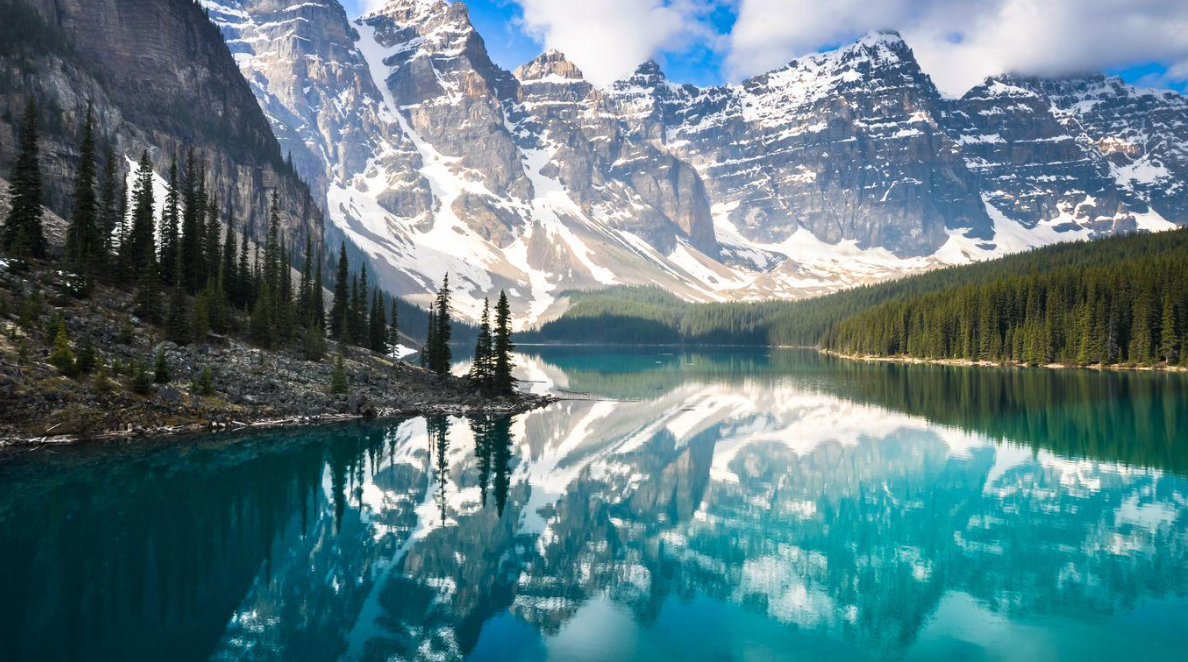

coffee (1).png (1191, 668)


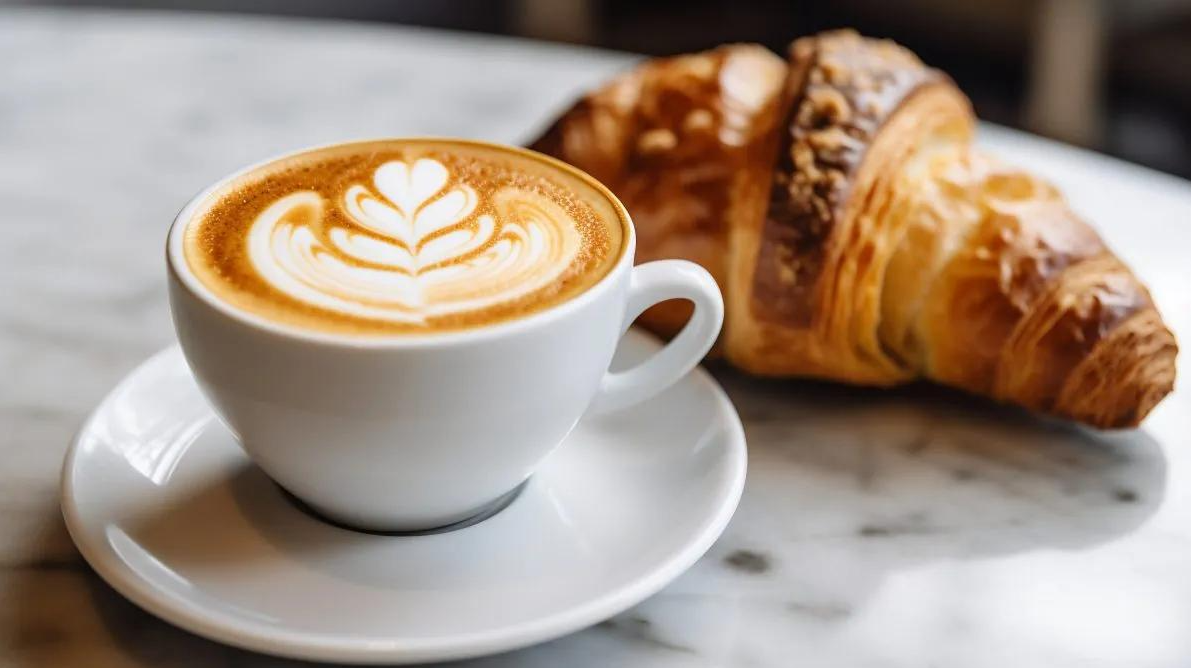

Happy Golden Retriever in the Park-1 (3).png (1536, 1024)


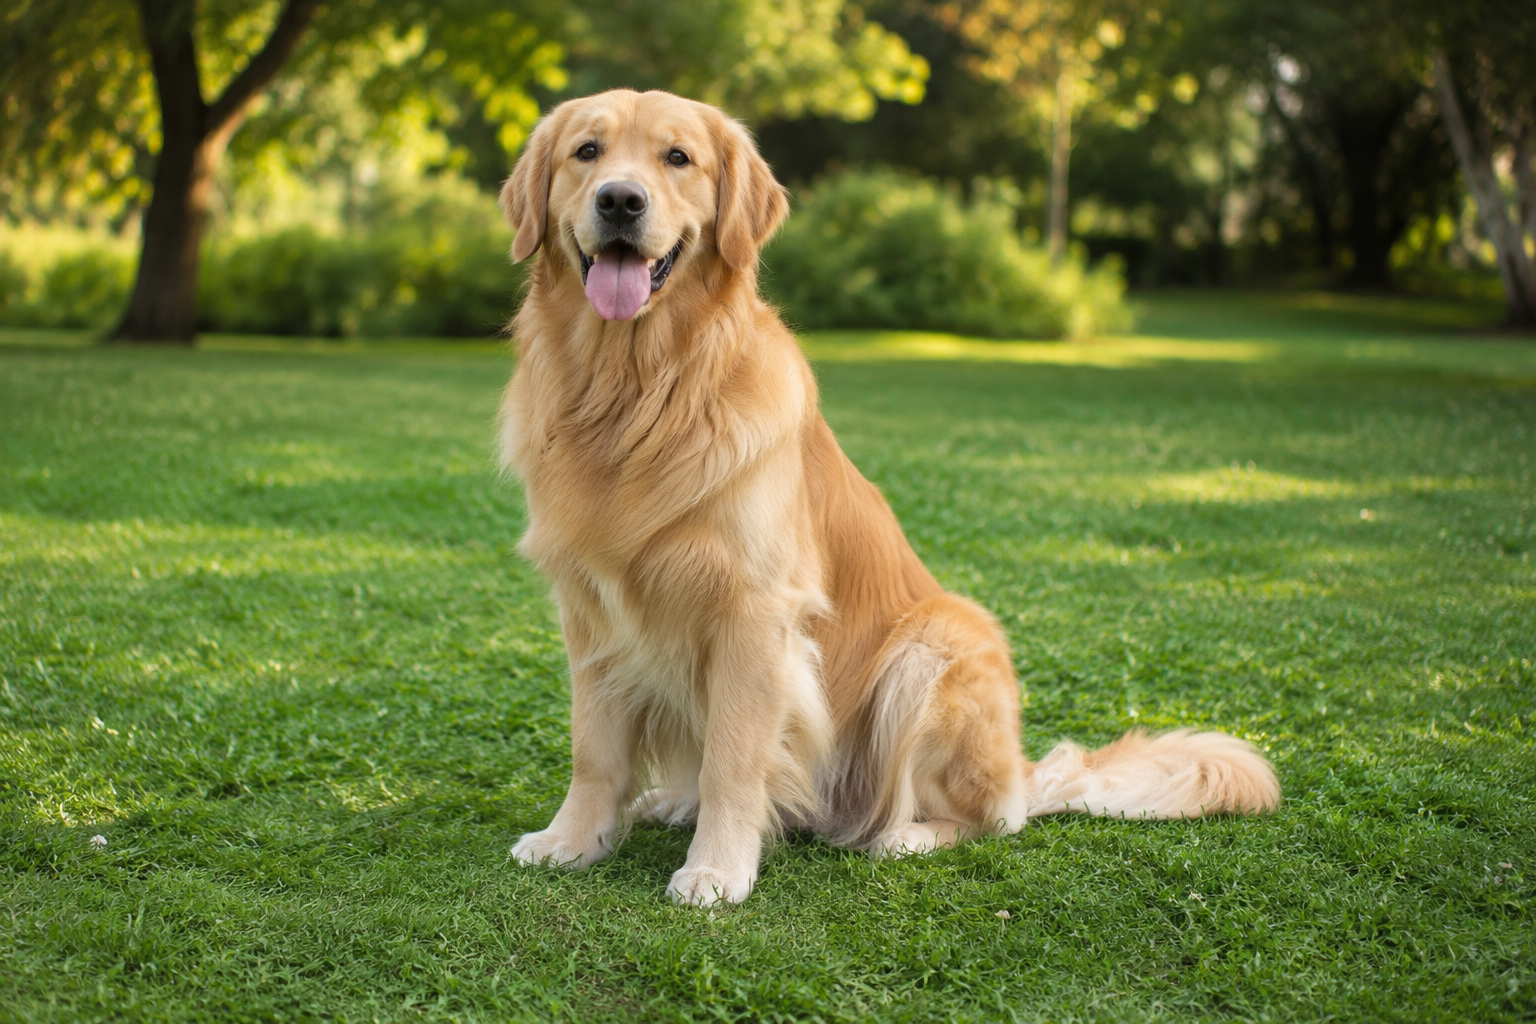

In [4]:
from google.colab import files

uploaded = files.upload()
if len(uploaded) < 2:
    raise ValueError("Upload at least two images to build a small retrieval collection.")

image_paths = list(uploaded.keys())
image_items = []

for path in image_paths:
    img = Image.open(path).convert("RGB")
    image_items.append({"path": path, "image": img})
    print(Path(path).name, img.size)
    display(img)


### 4. Create reusable embedding functions

The model returns projected image and text features. We normalize them so dot product is equivalent to cosine similarity.

In [5]:
processor = clip_processor

import torch
import torch.nn.functional as F

@torch.inference_mode()
def embed_images(images, batch_size=8):
    all_embeddings = []

    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size]

        inputs = processor(
            images=batch,
            return_tensors="pt"
        ).to(device)

        outputs = clip_model.vision_model(
            pixel_values=inputs["pixel_values"]
        )

        pooled_output = outputs.pooler_output
        features = clip_model.visual_projection(pooled_output)

        features = F.normalize(features, p=2, dim=-1)
        all_embeddings.append(features.cpu())

    return torch.cat(all_embeddings, dim=0)


@torch.inference_mode()
def embed_texts(texts, batch_size=16):
    all_embeddings = []

    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]

        inputs = processor(
            text=batch,
            return_tensors="pt",
            padding=True,
            truncation=True
        ).to(device)

        outputs = clip_model.text_model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"]
        )

        pooled_output = outputs.pooler_output
        features = clip_model.text_projection(pooled_output)

        features = F.normalize(features, p=2, dim=-1)
        all_embeddings.append(features.cpu())

    return torch.cat(all_embeddings, dim=0)


print("Updated image and text embedding functions ready.")


Updated image and text embedding functions ready.


### 5. Embed the image collection

Each image becomes one vector. We store the filename alongside the embedding so retrieval results can be traced back to the original file.

In [6]:
collection_images = [item["image"] for item in image_items]
image_embeddings = embed_images(collection_images)

image_metadata = [
    {"index": i, "filename": Path(item["path"]).name}
    for i, item in enumerate(image_items)
]

print("Image embedding shape:", tuple(image_embeddings.shape))
print("Number of indexed images:", len(image_metadata))


Image embedding shape: (3, 512)
Number of indexed images: 3


In [7]:
print([name for name in globals() if "processor" in name.lower()])

['CLIPProcessor', 'clip_processor', 'processor']


### 6. Text-to-image retrieval

Enter a natural-language query. CLIP embeds the query and compares it with all image embeddings. The highest cosine similarity is the nearest image in the collection.

In [8]:
def search_images(query, top_k=5):
    if not query.strip():
        raise ValueError("Enter a non-empty search query.")

    text_embedding = embed_texts([query]).squeeze(0)

    print("Image embeddings:", image_embeddings.shape)
    print("Text embedding:", text_embedding.shape)

    similarities = image_embeddings @ text_embedding
    similarities = similarities.reshape(-1)

    top_indices = torch.argsort(similarities, descending=True)[:top_k]

    results = []
    for idx in top_indices:
        i = idx.item()
        results.append({
            **image_metadata[i],
            "similarity": round(similarities[i].item(), 4)
        })

    return results


text_query = input("Enter a text query for image search: ").strip()
if not text_query:
    raise ValueError("Enter a non-empty search query.")

text_results = search_images(text_query, top_k=min(5, len(image_items)))
pd.DataFrame(text_results)


Enter a text query for image search: Find a relaxing outdoor scene
Image embeddings: torch.Size([3, 512])
Text embedding: torch.Size([512])


,index,filename,similarity
0,0,mountain (1).png,0.2486
1,2,Happy Golden Retriever in the Park-1 (3).png,0.2368
2,1,coffee (1).png,0.2059


### 7. Display retrieved images

mountain (1).png | cosine similarity: 0.2486


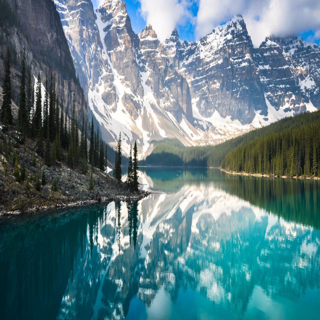

Happy Golden Retriever in the Park-1 (3).png | cosine similarity: 0.2368


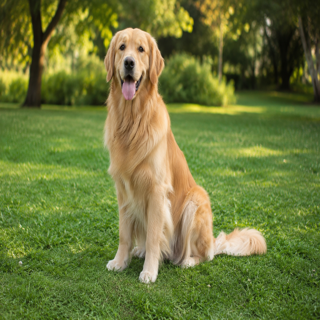

coffee (1).png | cosine similarity: 0.2059


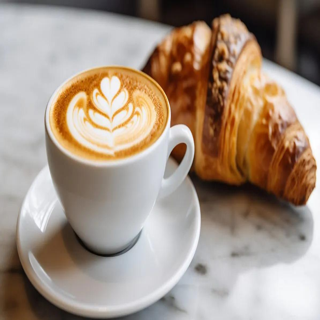

In [9]:
for result in text_results:
    item = image_items[result["index"]]
    print(
        f'{result["filename"]} | cosine similarity: '
        f'{result["similarity"]:.4f}'
    )
    display(item["image"].resize((320, 320)))


### 8. Image-to-text retrieval

Now provide candidate text descriptions. CLIP embeds each description and ranks them against a selected image embedding. This is image-to-text retrieval over a candidate list, not free-form caption generation.

Available images:
0 mountain (1).png
1 coffee (1).png
2 Happy Golden Retriever in the Park-1 (3).png
Enter the image index to search descriptions for: 0


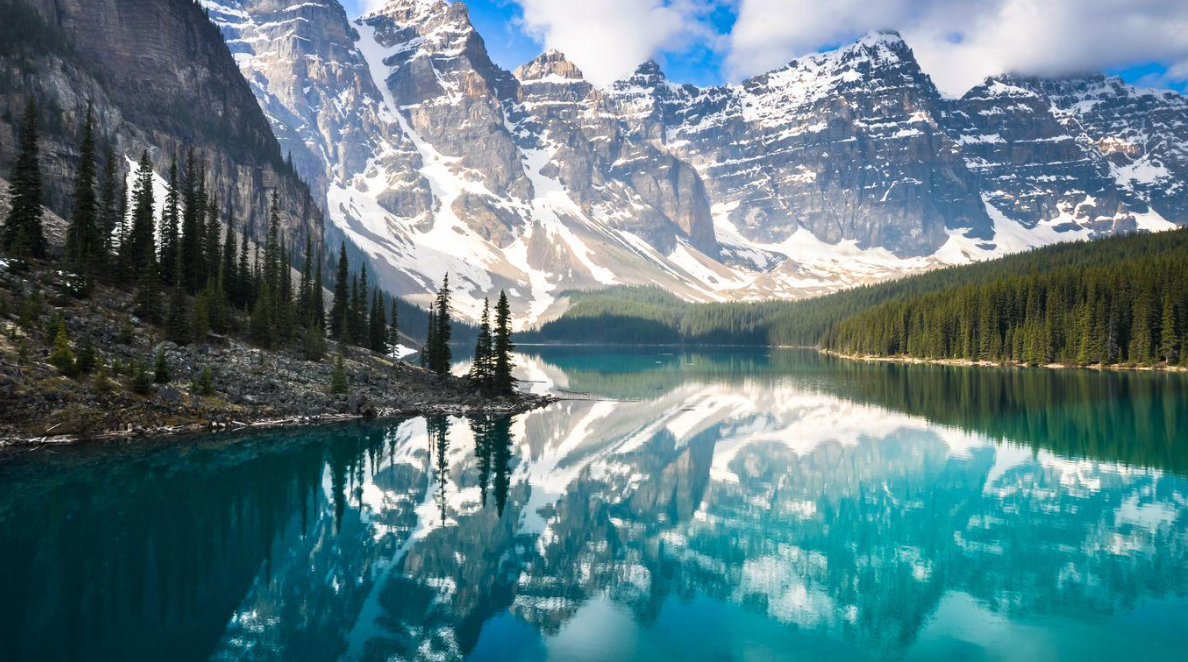

,description,similarity
0,A photo of a landscape.,0.242806
1,A photo of an animal.,0.205464
2,A photo of a building.,0.199486
3,A photo of a person.,0.198768
4,A photo of a vehicle.,0.189719
5,A document or printed page.,0.188239
6,A photo of an electronic device.,0.182030
7,A photo of food.,0.179297


In [10]:
print("Available images:")
for i, item in enumerate(image_items):
    print(i, Path(item["path"]).name)

selected_index = int(input("Enter the image index to search descriptions for: "))
if selected_index < 0 or selected_index >= len(image_items):
    raise IndexError("Image index is out of range.")

display(image_items[selected_index]["image"])

candidate_descriptions = [
    "A photo of a person.",
    "A photo of an animal.",
    "A photo of a vehicle.",
    "A photo of food.",
    "A photo of a building.",
    "A photo of a landscape.",
    "A photo of an electronic device.",
    "A document or printed page."
]

text_candidate_embeddings = embed_texts(candidate_descriptions)
selected_image_embedding = image_embeddings[selected_index].unsqueeze(0)
description_scores = (selected_image_embedding @ text_candidate_embeddings.T).squeeze(0)

ranked_descriptions = [
    {"description": candidate_descriptions[i], "similarity": float(description_scores[i])}
    for i in torch.argsort(description_scores, descending=True).tolist()
]

pd.DataFrame(ranked_descriptions)


### 9. Compare image-text pairs directly

This cell compares a set of custom descriptions against every image. It produces a similarity matrix. Higher values mean stronger relative alignment for this model and these candidates.

In [11]:
custom_descriptions = [
    "A close-up photograph of an object.",
    "A street scene with vehicles and buildings.",
    "A receipt or invoice with printed text.",
    "A natural landscape with trees and sky.",
    "A person standing outdoors."
]

custom_text_embeddings = embed_texts(custom_descriptions)
similarity_matrix = image_embeddings @ custom_text_embeddings.T

similarity_df = pd.DataFrame(
    similarity_matrix.numpy(),
    index=[m["filename"] for m in image_metadata],
    columns=custom_descriptions
)

similarity_df


,A close-up photograph of an object.,A street scene with vehicles and buildings.,A receipt or invoice with printed text.,A natural landscape with trees and sky.,A person standing outdoors.
mountain (1).png,0.173344,0.129304,0.166465,0.218904,0.204868
coffee (1).png,0.186483,0.123813,0.194287,0.103767,0.144070
Happy Golden Retriever in the Park-1 (3).png,0.195855,0.119316,0.162058,0.165372,0.220512


### 10. Visualize the similarity matrix

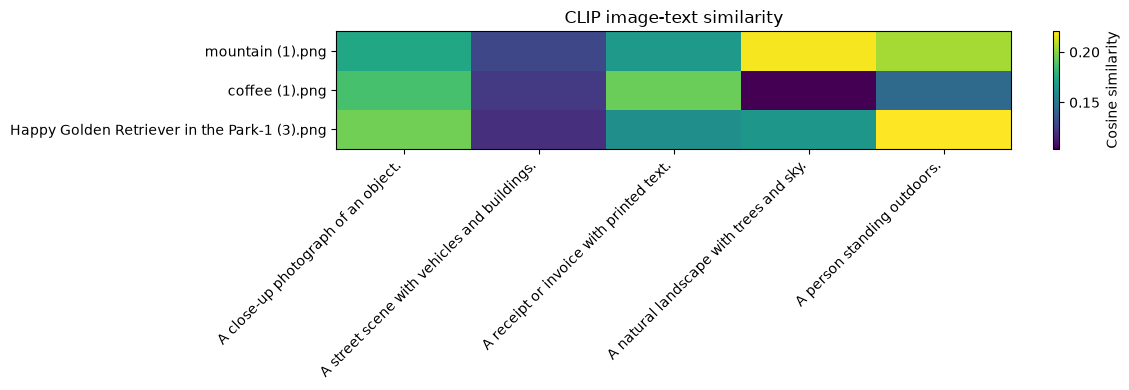

In [12]:
plt.figure(figsize=(12, max(4, len(image_items) * 0.7)))
plt.imshow(similarity_matrix.numpy(), aspect="auto")
plt.colorbar(label="Cosine similarity")
plt.xticks(range(len(custom_descriptions)), custom_descriptions, rotation=45, ha="right")
plt.yticks(range(len(image_metadata)), [m["filename"] for m in image_metadata])
plt.title("CLIP image-text similarity")
plt.tight_layout()
plt.show()


### 11. Save embeddings and metadata

The saved `.pt` file contains the image embedding tensor and metadata. Keep the original images as well: the embeddings refer to their order and filenames. The JSON file stores the retrieval examples and candidate descriptions.

In [13]:
embedding_path = Path("day5_clip_image_embeddings.pt")
torch.save({
    "model_id": MODEL_ID,
    "image_embeddings": image_embeddings,
    "image_metadata": image_metadata
}, embedding_path)

retrieval_record = {
    "module": 5,
    "day": 5,
    "model": MODEL_ID,
    "text_query": text_query,
    "text_to_image_results": text_results,
    "image_to_text_image": image_metadata[selected_index]["filename"],
    "image_to_text_results": ranked_descriptions,
    "custom_descriptions": custom_descriptions,
    "similarity_matrix": similarity_matrix.tolist(),
    "created_at": datetime.now().isoformat(timespec="seconds")
}

json_path = Path("day5_clip_retrieval_results.json")
json_path.write_text(
    json.dumps(retrieval_record, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("Saved:", embedding_path.resolve())
print("Saved:", json_path.resolve())


Saved: /content/day5_clip_image_embeddings.pt
Saved: /content/day5_clip_retrieval_results.json


### 12. Reuse the utilities later

These functions are the reusable primitives for Module 6. The image embedding function accepts PIL images; the text embedding function accepts a list of strings. Keep the model and processor loaded when embedding multiple batches.

For a larger collection, store embeddings in a vector index (for example, FAISS or a vector database) and retain metadata that maps each vector to its source image.

In [ ]:
# Example: embed a new image and compare it with the existing collection
# new_image_path = "path/to/new_image.jpg"
#
# new_image = Image.open(new_image_path).convert("RGB")
# new_embedding = embed_images([new_image])
# similarities = (new_embedding @ image_embeddings.T).squeeze(0)
# nearest_index = int(torch.argmax(similarities))
#
# print("Nearest existing image:", image_metadata[nearest_index]["filename"])
# print("Similarity:", float(similarities[nearest_index]))
